# Entrenamiento de modelo



In [ ]:
# Bibliotecas

import pandas as pd
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Definiciones globales

%run D:\Desarrollo\JupyterNotebooks\Modelo_deterioro_tramos_v02\Lib\pandas_options.py
    
%run D:\Desarrollo\JupyterNotebooks\Modelo_deterioro_tramos_v02\Lib\define_constantes.py

In [ ]:
# Cargar datos ya preprocesados y dividirlos en variables independientes (X) y variable dependiente objetivo (Y)

archivo_datos_codificados = f'{DIRECTORIO_DATOS}/DATOSCODIFICADOS.csv'
df_datos_codificados = pd.read_csv(archivo_datos_codificados, low_memory=False)

X = df_datos_codificados.drop('DETERIORADO', axis='columns')

Y = df_datos_codificados['DETERIORADO']

print(X.info())
print(X.head())
print(Y.info())
print(Y.value_counts().sort_index())

In [ ]:
# Entrenar modelo

modelo = LogisticRegression(C=5, class_weight={False: 1, True: 2}, max_iter=10000, n_jobs=-1, solver='newton-cholesky')

x_train, x_test, y_train, y_test = train_test_split(X, Y)
modelo.fit(x_train, y_train)
y_pred = modelo.predict(x_test)

In [ ]:
print(classification_report(y_test, y_pred))
conf_matrix = confusion_matrix(y_test, y_pred)
class_names = [False, True]
plt.figure(figsize=(8, 2))
plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greens', cbar=False, xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción deterioro', fontweight='bold')
plt.ylabel('Real', fontweight='bold')
plt.title('Matriz de confusión LSVC', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

# Ajuste de RECALL (Detección de positivos)

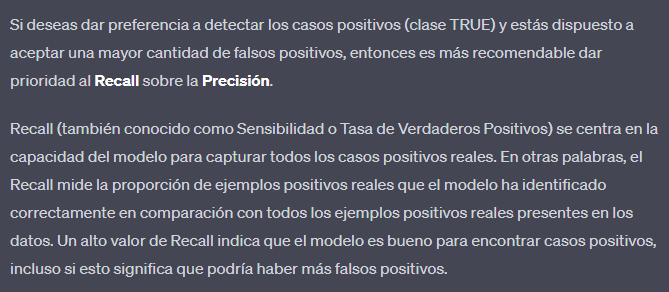

In [ ]:
# Obtener las probabilidades estimadas
probabilities = modelo.predict_proba(x_test)[:, 1]  # Probabilidades de la clase positiva

# Definir umbral
threshold = 0.38

# Obtener las predicciones ajustadas después de ajustar el umbral de decisión
adjusted_predictions = (probabilities > threshold).astype(int)

# Generar el classification_report con las nuevas predicciones ajustadas
report = classification_report(y_test, adjusted_predictions)

# Generar la matriz de confusión con las nuevas predicciones ajustadas
conf_matrix = confusion_matrix(y_test, adjusted_predictions)

# Imprimir el classification_report y la matriz de confusión
print(report)
plt.figure(figsize=(8, 2))
plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greens', cbar=False, xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción deteriorado', fontweight='bold')
plt.ylabel('Real', fontweight='bold')
plt.title('Matriz de confusión ajustada - Datos de prueba', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# Guardar modelo entrenado

archivo_modelo = f'{DIRECTORIO_MODELOS}/LGR-nc.joblib'
joblib.dump(modelo, archivo_modelo)
print(f'Guardado modelo en {archivo_modelo}')

In [ ]:
# Guardar columnas usadas

columnas_modelo = X.columns.to_list()
archivo_columnas = f'{DIRECTORIO_MODELOS}/COLUMNAS.txt'

with open(archivo_columnas, "w") as archivo:
    for col in columnas_modelo:
        archivo.write(col + '\n')

print(columnas_modelo)